In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
image_path = '/content/drive/MyDrive/path_to_your_image.jpg'

In [4]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


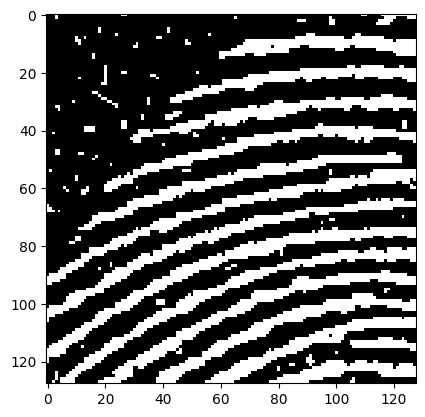

In [9]:
img_ORG = plt.imread('/content/drive/MyDrive/Colab Notebooks/fingerprint.png')
img = (img_ORG[:, :, 0] >= 0.5) * 1
plt.imshow(img, interpolation='nearest', cmap='gray')
plt.show()

In [11]:
def an_mon(img, ptct):
    w, h = img.shape

    sumptct = np.sum(ptct)
    le_tp = (ptct.shape[0]-1)//2 #lễ trái phải
    le_td = (ptct.shape[1]-1)//2 #lễ trên dưới

    img_kq = np.zeros_like(img)

    for i in range(le_td, h - le_td):
        for j in range(le_tp, h - le_tp):
            cat_hinh_goc = img[i-le_td:i+le_td+1, j-le_tp:j+le_tp+1]
            #...
            #img_kq[i, j] =...
    return img_kq

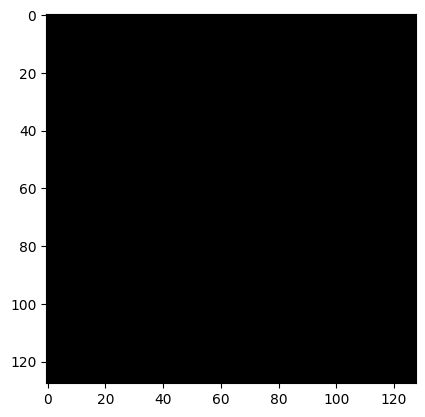

In [12]:
ptct = np.array ( [ [1, 1, 1], [1, 1, 1], [1, 1, 1]])
plt.imshow(an_mon(img, ptct), interpolation='nearest', cmap= 'gray')
plt.show()

In [13]:
#Phan 2 gian no
def gian_no(img, ptct):
    w, h = img.shape

    le_tp = (ptct.shape[0]-1)//2 # lề trái phải
    le_td = (ptct.shape[1]-1)//2 # lề trên dưới

    img_kq = np.zeros_like(img)

    for i in range(le_td, h - le_td):
        for j in range(le_tp, h - le_tp):
            cat_hinh_goc = img[i-le_td:i+le_td+1, j-le_tp:j+le_tp+1]
            img_kq[i, j] = np.max(cat_hinh_goc * ptct)

    return img_kq

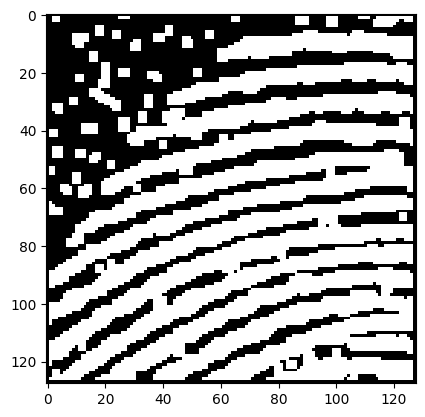

In [14]:
ptct = np.array([[1, 1, 1], [1, 1, 1], [1, 1, 1]])
plt.imshow(gian_no(img, ptct), interpolation='nearest', cmap='gray')
plt.show()

In [19]:
#Phan 3
def HMT(img, ptct):
    w, h = img.shape
    img_out = np.zeros_like(img)
    ptct0 = (ptct == 0)*1
    sum0 = np.sum(ptct0)
    ptct1 = (ptct == 1)*1
    sum1 = np.sum(ptct1)

    for i in range(1, h - 1):
        for j in range(1, w - 1):
            cat_hinh_goc = img[i-1:i+2, j-1:j+2]

            X = cat_hinh_goc * ptct1
            OK1 = 1 if np.sum(X) == sum1 else 0

            X = (1 - cat_hinh_goc) * ptct0
            OK0 = 1 if np.sum(X) == sum0 else 0

            img_out[i, j] = OK0 * OK1

    return img_out

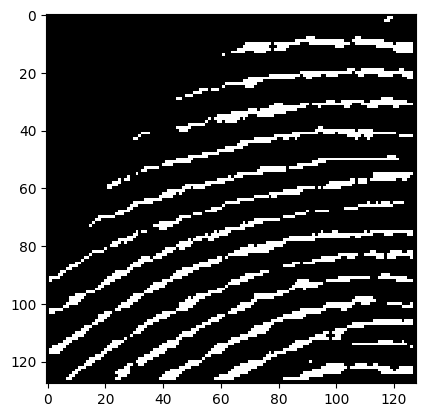

In [20]:
ptct = np.array ( [ [0.5, 1, 0.5], [1, 1, 1], [0.5, 1, 0.5]])
plt.imshow(HMT(img, ptct), interpolation='nearest', cmap= 'gray')
plt.show()

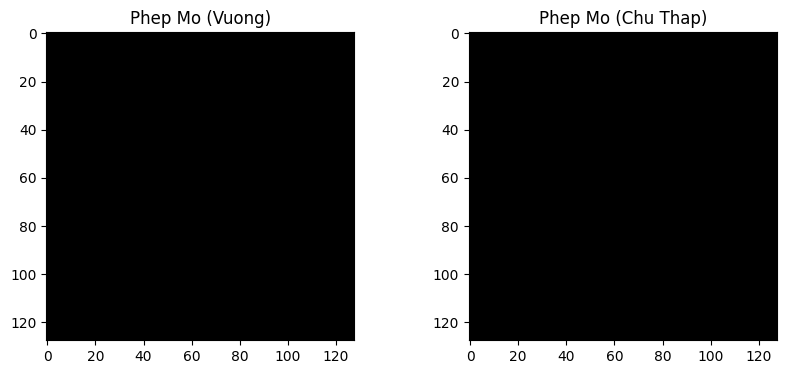

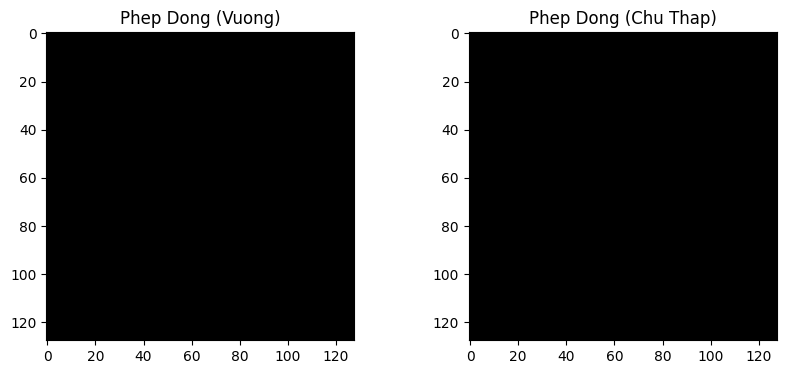

In [21]:
# phép Mở (Ăn mòn rồi Giãn nở)
def phep_mo(img, ptct):
    return gian_no(an_mon(img, ptct), ptct)

#phép Đóng (Giãn nở rồi Ăn mòn)
def phep_dong(img, ptct):
    return an_mon(gian_no(img, ptct), ptct)

#ví dụ:hình vuông, chữ thập
ptct_vuong = np.array([[1, 1, 1],
                       [1, 1, 1],
                       [1, 1, 1]])

ptct_chuthap = np.array([[0, 1, 0],
                         [1, 1, 1],
                         [0, 1, 0]])

# kết quả Phép Mở
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(phep_mo(img, ptct_vuong), interpolation='nearest', cmap='gray')
plt.title('Phep Mo (Vuong)')

plt.subplot(1, 2, 2)
plt.imshow(phep_mo(img, ptct_chuthap), interpolation='nearest', cmap='gray')
plt.title('Phep Mo (Chu Thap)')
plt.show()

#kết quả Phép Đóng
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(phep_dong(img, ptct_vuong), interpolation='nearest', cmap='gray')
plt.title('Phep Dong (Vuong)')

plt.subplot(1, 2, 2)
plt.imshow(phep_dong(img, ptct_chuthap), interpolation='nearest', cmap='gray')
plt.title('Phep Dong (Chu Thap)')
plt.show()

In [22]:
#Cau 2
#Ý nghĩa: Giá trị 0.5 trong ptct tượng trưng cho trạng thái "Không quan tâm" (Don't care),
#tức là vị trí đó sẽ được bỏ qua và không xét điều kiện khớp (0 hay 1) trong hàm HMT.

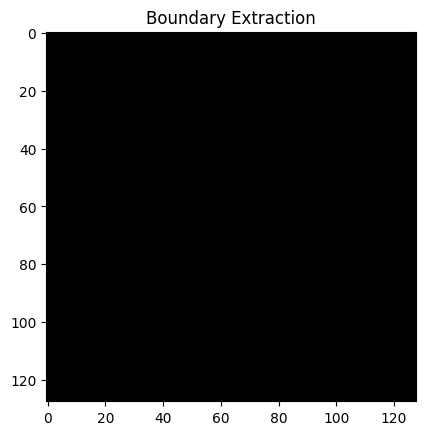

In [23]:
#phần tử cấu trúc cho trích xuất biên
ptct_boundary = np.array([[0, 1, 0],
                          [1, 1, 1],
                          [0, 1, 0]])
plt.imshow(HMT(img, ptct_boundary), interpolation='nearest', cmap='gray')
plt.title('Boundary Extraction')
plt.show()

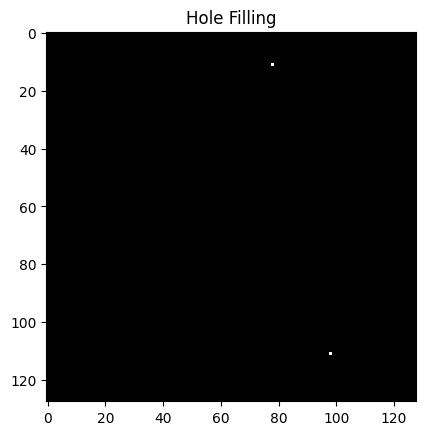

In [24]:
ptct_hole = np.array([[1, 1, 1],
                      [1, 0, 1],
                      [1, 1, 1]])
plt.imshow(HMT(img, ptct_hole), interpolation='nearest', cmap='gray')
plt.title('Hole Filling')
plt.show()

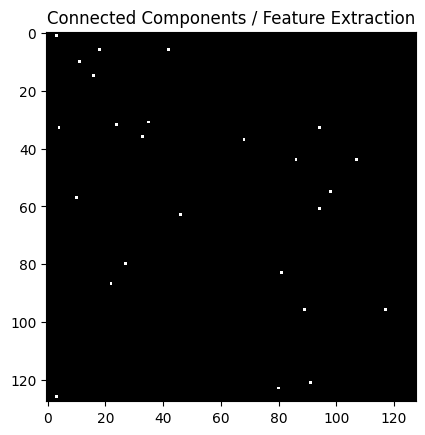

In [25]:
ptct_cc = np.array([[0.5, 1, 0.5],
                    [0,   1, 0  ],
                    [0.5, 0, 0.5]])
plt.imshow(HMT(img, ptct_cc), interpolation='nearest', cmap='gray')
plt.title('Connected Components / Feature Extraction')
plt.show()